In [30]:
import numpy as np
import tensorflow as tf
from sklearn.model_selection import train_test_split
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import Perceptron
from sklearn.metrics import accuracy_score,classification_report,confusion_matrix

from tensorflow.keras.models import Sequential
#this lets me build neural network layer by layer in keras
from tensorflow.keras.layers import Dense #dense makes the final prediction
from tensorflow.keras.layers import Conv2D #conv2d extract features
from tensorflow.keras.layers import Flatten #flatter reshape kore

from tensorflow.keras.layers import MaxPool2D #maxpooling kore- size reduce
from tensorflow.keras.layers import Dropout
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

from tensorflow.keras.utils import to_categorical #converts numerical into labels into one hot encoding format

In [31]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("abenjelloun/breast-mri-tumor-classification-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'breast-mri-tumor-classification-dataset' dataset.
Path to dataset files: /kaggle/input/breast-mri-tumor-classification-dataset


In [32]:
import os

dataset_path = path

# check inside folders
for dir_name,subdir,filenames in os.walk(dataset_path):
    for filename in filenames:
        print(os.path.join(dir_name,filename))

/kaggle/input/breast-mri-tumor-classification-dataset/breast_mri_dataset_original_shape/val/Benign/BREASTDX-01-0036_727.jpg
/kaggle/input/breast-mri-tumor-classification-dataset/breast_mri_dataset_original_shape/val/Benign/BREASTDX-01-0007_367.jpg
/kaggle/input/breast-mri-tumor-classification-dataset/breast_mri_dataset_original_shape/val/Benign/BREASTDX-01-0066_1951.jpg
/kaggle/input/breast-mri-tumor-classification-dataset/breast_mri_dataset_original_shape/val/Benign/BREASTDX-01-0004_1782.jpg
/kaggle/input/breast-mri-tumor-classification-dataset/breast_mri_dataset_original_shape/val/Benign/BREASTDX-01-0001_1990.jpg
/kaggle/input/breast-mri-tumor-classification-dataset/breast_mri_dataset_original_shape/val/Benign/BREASTDX-01-0035_60.jpg
/kaggle/input/breast-mri-tumor-classification-dataset/breast_mri_dataset_original_shape/val/Benign/BREASTDX-01-0028_2091.jpg
/kaggle/input/breast-mri-tumor-classification-dataset/breast_mri_dataset_original_shape/val/Benign/BREASTDX-01-0012_404.jpg
/kagg

In [33]:
import os
import matplotlib.pyplot as plt
from PIL import Image

# Base path from the kagglehub download
BASE_PATH = os.path.join(path, 'breast_mri_dataset_original_shape')

splits = ['train', 'val', 'test']
classes = ['Benign', 'Malignant']

# Count images per split per class
print(f"{'Split':<10} {'Benign':<12} {'Malignant':<12} {'Total'}")
print("-" * 44)
for split in splits:
    counts = {}
    for cls in classes:
        folder = os.path.join(BASE_PATH, split, cls)
        counts[cls] = len(os.listdir(folder))
    total = sum(counts.values())
    print(f"{split:<10} {counts['Benign']:<12} {counts['Malignant']:<12} {total}")

Split      Benign       Malignant    Total
--------------------------------------------
train      8413         8413         16826
val        1797         1797         3594
test       1802         1802         3604


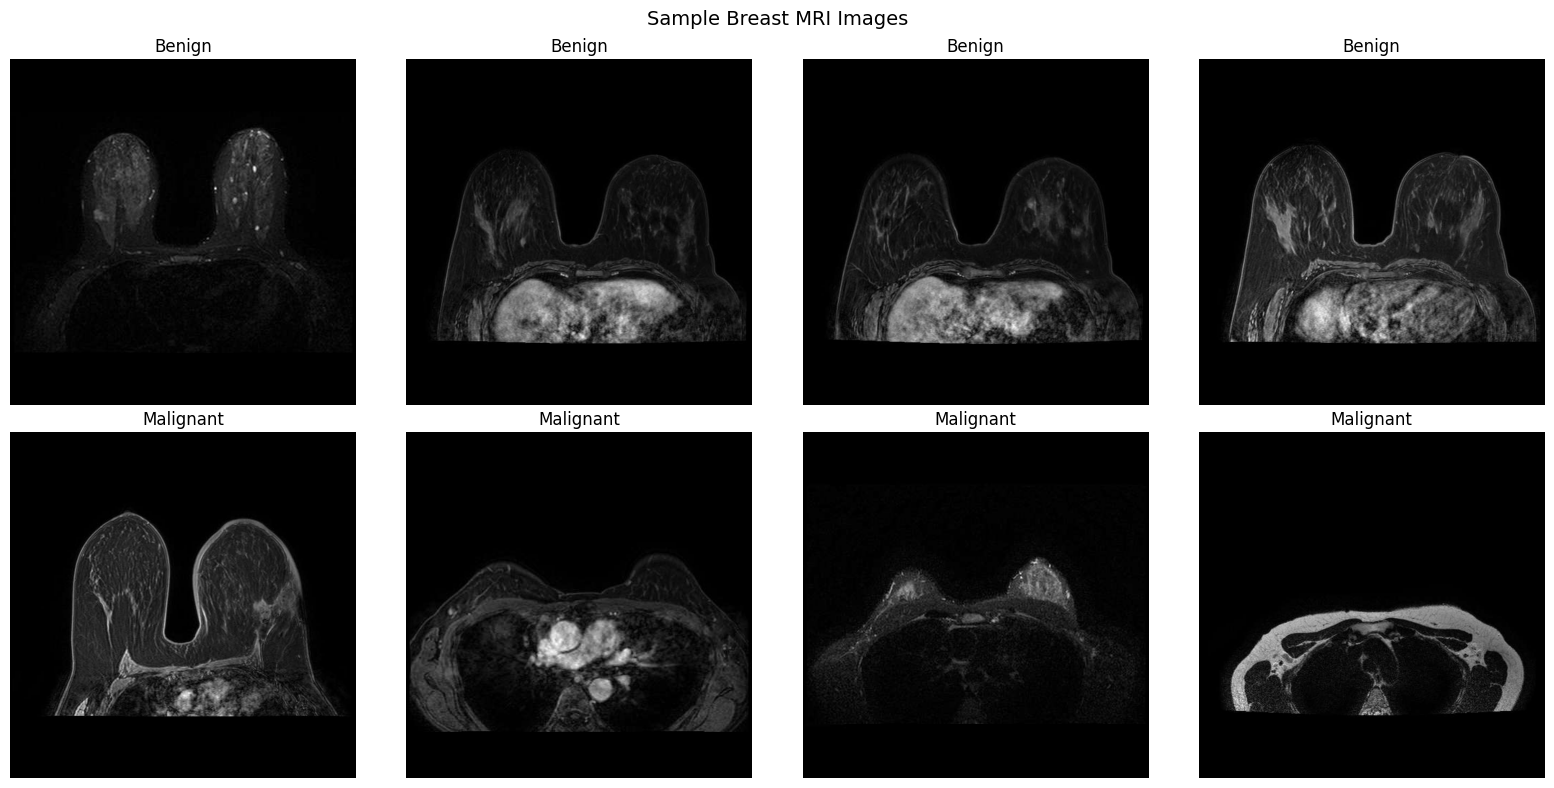

In [34]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
fig.suptitle("Sample Breast MRI Images", fontsize=14)

for row, cls in enumerate(classes):
    folder = os.path.join(BASE_PATH, 'train', cls)
    sample_imgs = os.listdir(folder)[:4]
    for col, fname in enumerate(sample_imgs):
        img = Image.open(os.path.join(folder, fname)).convert('RGB')
        axes[row][col].imshow(img, cmap='gray')
        axes[row][col].set_title(f"{cls}")
        axes[row][col].axis('off')

plt.tight_layout()
plt.show()

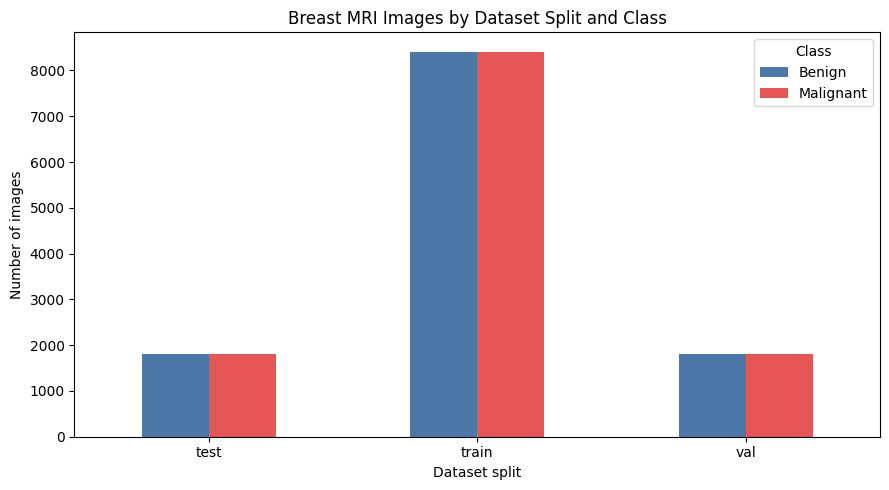

In [35]:
# Plot the class distribution for each dataset split
count_data = []
for split in splits:
    for cls in classes:
        folder = os.path.join(BASE_PATH, split, cls)
        count_data.append({
            'Split': split,
            'Class': cls,
            'Images': len(os.listdir(folder))
        })

count_df = pd.DataFrame(count_data)
count_plot = count_df.pivot(index='Split', columns='Class', values='Images')

ax = count_plot.plot(kind='bar', figsize=(9, 5), color=['#4C78A8', '#E45756'])
ax.set_title('Breast MRI Images by Dataset Split and Class')
ax.set_xlabel('Dataset split')
ax.set_ylabel('Number of images')
ax.tick_params(axis='x', rotation=0)
ax.legend(title='Class')
plt.tight_layout()
plt.show()

In [36]:
import tensorflow as tf
import os

IMG_SIZE = (224, 224)
BATCH_SIZE = 32

# Create optimized datasets (images remain unscaled in 0-255 range here; model will handle scaling)
train_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(BASE_PATH, 'train'),
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='binary',
    color_mode='rgb',
    shuffle=True
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(BASE_PATH, 'val'),
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='binary',
    color_mode='rgb',
    shuffle=False
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    os.path.join(BASE_PATH, 'test'),
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='binary',
    color_mode='rgb',
    shuffle=False
)

# Configure performance optimization with prefetching
AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.prefetch(buffer_size=AUTOTUNE)

print("Optimized tf.data Datasets ready!")

Found 16826 files belonging to 2 classes.
Found 3594 files belonging to 2 classes.
Found 3604 files belonging to 2 classes.
Optimized tf.data Datasets ready!


In [48]:
# Define the data augmentation sequential block
data_augmentation = Sequential([
    tf.keras.layers.Rescaling(1./255), # Rescale pixel values [0, 255] to [0.0, 1.0]
    tf.keras.layers.RandomRotation(0.027),
    tf.keras.layers.RandomZoom(0.1),
    tf.keras.layers.RandomTranslation(height_factor=0.05, width_factor=0.05),
    tf.keras.layers.RandomFlip("horizontal")
])

# Building the CNN with Integrated Augmentation Layers
CNN = Sequential([
    # Input layer specification
    tf.keras.layers.Input(shape=(224, 224, 3)),

    # Augmentation & Rescaling layers (Only active during training, auto-bypassed during validation/testing)
    data_augmentation,

    # Feature Extraction Convolutional Blocks
    Conv2D(32, (3, 3), activation='relu'),
    MaxPool2D(2, 2),

    Conv2D(64, (3, 3), activation='relu'),
    MaxPool2D(2, 2),

    Conv2D(128, (3, 3), activation='relu'),
    MaxPool2D(2, 2),

    # Fully Connected Dense Classifier
    Flatten(),
    Dense(512, activation='relu'),
    Dropout(0.5),
    Dense(1, activation='sigmoid')
])

CNN.summary()

Model: "sequential_7"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_6 (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 512)            │    44,302,848 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 1)              │           513 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 44,396,609 (169.36 MB)

 Trainable params: 44,396,609 (169.36 MB)

 Non-trainable params: 0 (0.00 B)

In [49]:
CNN.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy',tf.keras.metrics.AUC(name='auc')] #auc for medical
)

In [ ]:
callbacks = [
    EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True),
    ModelCheckpoint('best_breast_mri_model.keras', monitor='val_auc', save_best_only=True, mode='max'),
    ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, verbose=1)
]

# Start high-speed training on pre-fetched TF datasets with native GPU augmentations!
history = CNN.fit(
    train_ds,
    epochs=5,
    validation_data=val_ds,
    callbacks=callbacks
)

Epoch 1/10
526/526 ━━━━━━━━━━━━━━━━━━━━ 62s 111ms/step - accuracy: 0.6300 - auc: 0.6837 - loss: 0.6398 - val_accuracy: 0.7284 - val_auc: 0.8108 - val_loss: 0.5349 - learning_rate: 0.0010
Epoch 2/10
526/526 ━━━━━━━━━━━━━━━━━━━━ 56s 106ms/step - accuracy: 0.7315 - auc: 0.8039 - loss: 0.5327 - val_accuracy: 0.7972 - val_auc: 0.8945 - val_loss: 0.4220 - learning_rate: 0.0010
Epoch 3/10
526/526 ━━━━━━━━━━━━━━━━━━━━ 52s 98ms/step - accuracy: 0.7695 - auc: 0.8580 - loss: 0.4609 - val_accuracy: 0.8570 - val_auc: 0.9403 - val_loss: 0.3136 - learning_rate: 0.0010
Epoch 4/10
526/526 ━━━━━━━━━━━━━━━━━━━━ 62s 118ms/step - accuracy: 0.8129 - auc: 0.8997 - loss: 0.3942 - val_accuracy: 0.8932 - val_auc: 0.9666 - val_loss: 0.2475 - learning_rate: 0.0010
Epoch 5/10
526/526 ━━━━━━━━━━━━━━━━━━━━ 60s 115ms/step - accuracy: 0.8402 - auc: 0.9249 - loss: 0.3445 - val_accuracy: 0.8873 - val_auc: 0.9686 - val_loss: 0.2457 - learning_rate: 0.0010
Epoch 6/10
526/526 ━━━━━━━━━━━━━━━━━━━━ 52s 98ms/step - accuracy: 

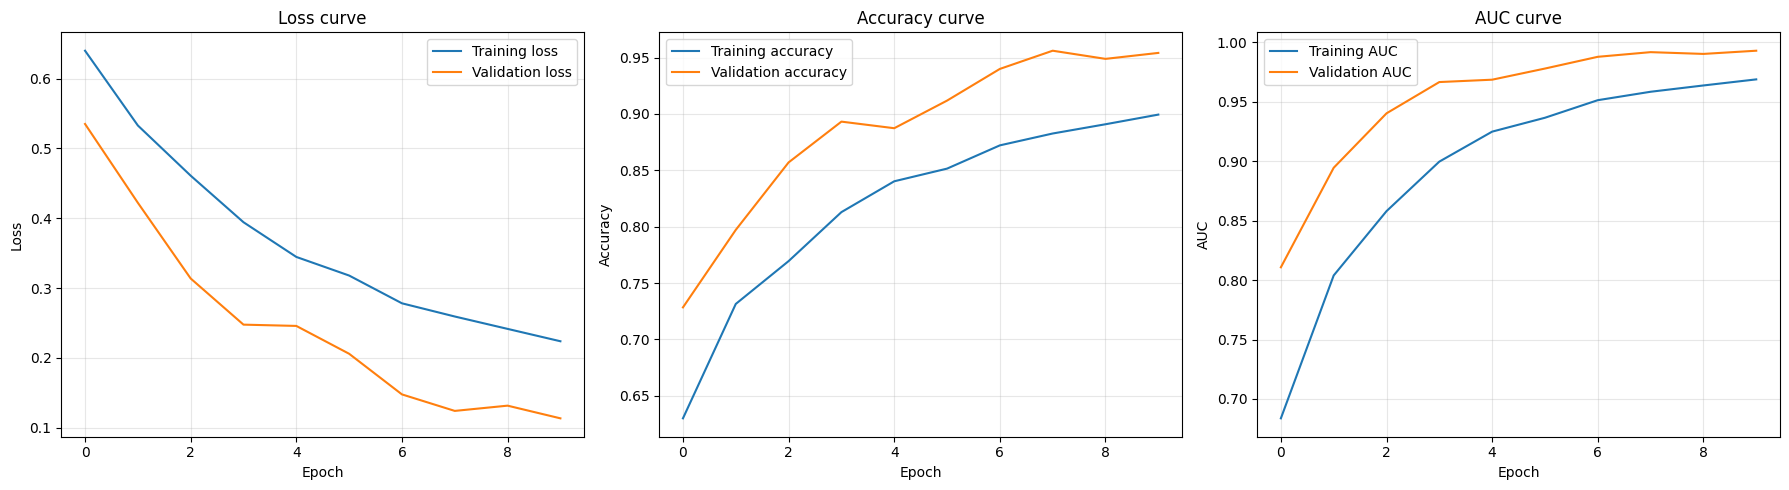

113/113 ━━━━━━━━━━━━━━━━━━━━ 7s 59ms/step


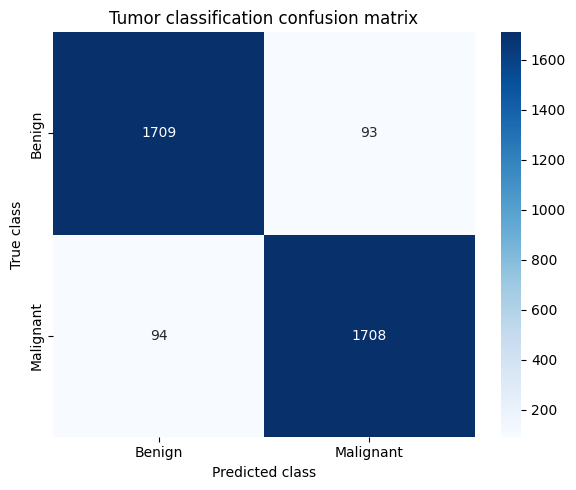

              precision    recall  f1-score   support

      Benign       0.95      0.95      0.95      1802
   Malignant       0.95      0.95      0.95      1802

    accuracy                           0.95      3604
   macro avg       0.95      0.95      0.95      3604
weighted avg       0.95      0.95      0.95      3604

Test accuracy: 0.9481


In [40]:
# Plot training curves and evaluate tumor classification on the test set
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].plot(history.history['loss'], label='Training loss')
axes[0].plot(history.history['val_loss'], label='Validation loss')
axes[0].set_title('Loss curve')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(history.history['accuracy'], label='Training accuracy')
axes[1].plot(history.history['val_accuracy'], label='Validation accuracy')
axes[1].set_title('Accuracy curve')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].legend()
axes[1].grid(alpha=0.3)

axes[2].plot(history.history['auc'], label='Training AUC')
axes[2].plot(history.history['val_auc'], label='Validation AUC')
axes[2].set_title('AUC curve')
axes[2].set_xlabel('Epoch')
axes[2].set_ylabel('AUC')
axes[2].legend()
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()

# Generate predictions for every test image
true_labels = np.concatenate([labels.numpy().ravel() for _, labels in test_ds]).astype(int)
predicted_probabilities = CNN.predict(test_ds, verbose=1).ravel()
predicted_labels = (predicted_probabilities >= 0.5).astype(int)

confusion = confusion_matrix(true_labels, predicted_labels)
plt.figure(figsize=(6, 5))
sns.heatmap(
    confusion,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=classes,
    yticklabels=classes
)
plt.title('Tumor classification confusion matrix')
plt.xlabel('Predicted class')
plt.ylabel('True class')
plt.tight_layout()
plt.show()

print(classification_report(true_labels, predicted_labels, target_names=classes))
print(f"Test accuracy: {accuracy_score(true_labels, predicted_labels):.4f}")

True class: Benign
Predicted class: Malignant
Malignant probability: 0.5019
Grad-CAM explains: Malignant
Grad-CAM layer: conv2d_11


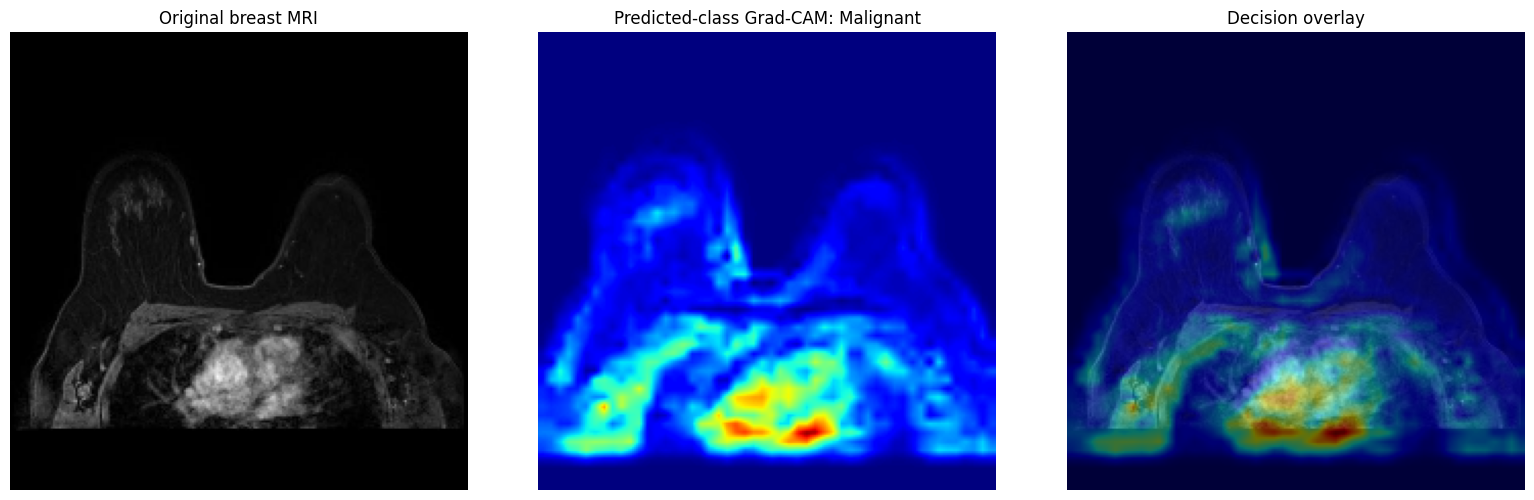

In [51]:
# Grad-CAM: visualize regions supporting the model's predicted class
last_conv_layer = next(
    layer for layer in reversed(CNN.layers)
    if isinstance(layer, tf.keras.layers.Conv2D)
)

# Use the first test image. Change image_index to inspect another image.
image_index = 0
image_batch, label_batch = next(iter(test_ds))
image = image_batch[image_index:image_index + 1]
true_label = int(label_batch.numpy().ravel()[image_index])

with tf.GradientTape() as tape:
    layer_output = image
    conv_outputs = None
    for layer in CNN.layers:
        layer_output = layer(layer_output, training=False)
        if layer is last_conv_layer:
            conv_outputs = layer_output
    prediction = layer_output
    malignant_probability = prediction[:, 0]
    predicted_label = tf.cast(malignant_probability >= 0.5, tf.int32)
    target_score = tf.where(
        predicted_label == 1,
        malignant_probability,
        1.0 - malignant_probability
    )

grads = tape.gradient(target_score, conv_outputs)
pooled_grads = tf.reduce_mean(grads, axis=(1, 2))
conv_outputs = conv_outputs[0]
pooled_grads = pooled_grads[0]
heatmap = tf.reduce_sum(conv_outputs * pooled_grads, axis=-1)
heatmap = tf.maximum(heatmap, 0)
heatmap /= tf.maximum(tf.reduce_max(heatmap), tf.keras.backend.epsilon())
heatmap = heatmap.numpy()

# Resize the heatmap and blend it with the original MRI image.
original_image = image[0].numpy().astype('uint8')
heatmap_resized = tf.image.resize(heatmap[..., np.newaxis], IMG_SIZE).numpy().squeeze()
heatmap_rgb = plt.get_cmap('jet')(heatmap_resized)[..., :3]
overlay = (0.55 * original_image / 255.0 + 0.45 * heatmap_rgb)
overlay = np.clip(overlay, 0, 1)

predicted_label = int(predicted_label[0].numpy())
malignant_probability = float(malignant_probability[0].numpy())
print(f"True class: {classes[true_label]}")
print(f"Predicted class: {classes[predicted_label]}")
print(f"Malignant probability: {malignant_probability:.4f}")
print(f"Grad-CAM explains: {classes[predicted_label]}")
print(f"Grad-CAM layer: {last_conv_layer.name}")

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
axes[0].imshow(original_image, cmap='gray')
axes[0].set_title('Original breast MRI')
axes[1].imshow(heatmap_resized, cmap='jet', vmin=0, vmax=1)
axes[1].set_title(f"Predicted-class Grad-CAM: {classes[predicted_label]}")
axes[2].imshow(original_image, cmap='gray')
axes[2].imshow(heatmap_resized, cmap='jet', alpha=0.45, vmin=0, vmax=1)
axes[2].set_title('Decision overlay')
for axis in axes:
    axis.axis('off')
plt.tight_layout()
plt.show()